Week 3 libraries loaded. Ready to shrink some data!
Target variable: close
Features used: ['open', 'high', 'low', 'volume']

--- PCR (Principal Component Regression) Results ---
Test R-squared:  0.9976
Test RMSE error: 0.1092

--- PLSR (Partial Least Squares) Results ---
Test R-squared:  0.9976
Test RMSE error: 0.1090


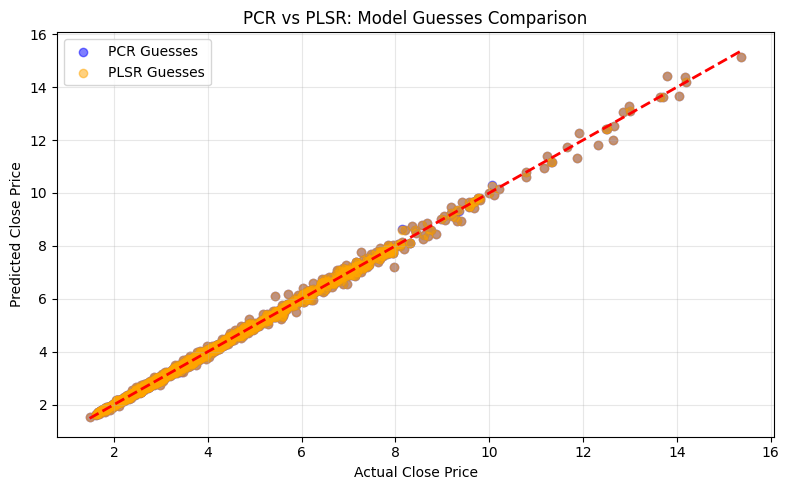

In [1]:
# Step 1: Get the libraries ready for Week 3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

print("Week 3 libraries loaded. Ready to shrink some data!")

# Step 2: Load our gas dataset from GitHub
link_gas = "https://raw.githubusercontent.com/JSFranco-DS/DX699S/main/Natural_Gas_data.csv"
df_gas = pd.read_csv(link_gas)

# Set our target (what we want to predict)
y_name = 'close'

# Grab all the number columns so we don't break the math
num_cols = df_gas.select_dtypes(include=[np.number]).columns.tolist()

if y_name in num_cols:
    num_cols.remove(y_name)

# Drop missing values so the models run smoothly
clean_df = df_gas[[y_name] + num_cols].dropna()

# Let's just use 4 numeric features this time to keep it simple
X = clean_df[num_cols[:4]]
y = clean_df[y_name]

print("Target variable:", y_name)
print("Features used:", X.columns.tolist())

# Step 3: Split into Train and Test sets, then Scale
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling is super important here so PCA doesn't get confused by big units
my_scaler = StandardScaler()
X_train_scaled = my_scaler.fit_transform(X_train)
X_test_scaled = my_scaler.transform(X_test)

# Step 4: Principal Component Regression (PCR)
# PCA finds new components that maximize variance, but it ignores our target variable (Y).
my_pca = PCA(n_components=2) # Shrink our 4 features down to 2
X_train_pca = my_pca.fit_transform(X_train_scaled)
X_test_pca = my_pca.transform(X_test_scaled)

pcr_model = LinearRegression()
pcr_model.fit(X_train_pca, y_train)

pcr_guess = pcr_model.predict(X_test_pca)

print("\n--- PCR (Principal Component Regression) Results ---")
print(f"Test R-squared:  {r2_score(y_test, pcr_guess):.4f}")
print(f"Test RMSE error: {np.sqrt(mean_squared_error(y_test, pcr_guess)):.4f}")

# Step 5: Partial Least Squares Regression (PLSR)
# PLSR is smarter because it looks at our target (Y) to make components that actually matter.
pls_model = PLSRegression(n_components=2)
pls_model.fit(X_train_scaled, y_train)

# We use .ravel() here because PLSR outputs a 2D array and we just want a flat list of numbers
pls_guess = pls_model.predict(X_test_scaled).ravel()

print("\n--- PLSR (Partial Least Squares) Results ---")
print(f"Test R-squared:  {r2_score(y_test, pls_guess):.4f}")
print(f"Test RMSE error: {np.sqrt(mean_squared_error(y_test, pls_guess)):.4f}")

# Step 6: Draw the comparison graph for the milestone report
# Let's put both PCR and PLSR on the same graph to see which one guessed better
plt.figure(figsize=(8, 5))
plt.scatter(y_test, pcr_guess, alpha=0.5, color='blue', label='PCR Guesses')
plt.scatter(y_test, pls_guess, alpha=0.5, color='orange', label='PLSR Guesses')

# Draw a red dashed line to show where perfect guesses would land
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)

plt.xlabel("Actual Close Price")
plt.ylabel("Predicted Close Price")
plt.title("PCR vs PLSR: Model Guesses Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()